In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules

from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.impute import SimpleImputer

import warnings
warnings.filterwarnings('ignore')

In [2]:
def duplicate_rows(df):
    return df[df.duplicated()]

def rows_with_missing_values(df):
    return df[df.isnull().any(axis=1)]

def format_rule(row):
    return f"{set(row['antecedents'])} => {set(row['consequents'])}"

In [3]:
data = pd.read_csv('house-votes-84.csv', na_values='?')
data

,Class Name,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
0,republican,n,y,n,y,y,y,n,n,n,y,NaN,y,y,y,n,y
1,republican,n,y,n,y,y,y,n,n,n,n,n,y,y,y,n,NaN
2,democrat,NaN,y,y,NaN,y,y,n,n,n,n,y,n,y,y,n,n
3,democrat,n,y,y,n,NaN,y,n,n,n,n,y,n,y,n,n,y
4,democrat,y,y,y,n,y,y,n,n,n,n,y,NaN,y,y,y,y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,republican,n,n,y,y,y,y,n,n,y,y,n,y,y,y,n,y
431,democrat,n,n,y,n,n,n,y,y,y,y,n,n,n,n,n,y
432,republican,n,NaN,n,y,y,y,n,n,n,n,y,y,y,y,n,y
433,republican,n,n,n,y,y,y,NaN,NaN,NaN,NaN,n,y,y,y,n,y


In [4]:
data.describe().T

,count,unique,top,freq
Class Name,435,2,democrat,267
handicapped-infants,423,2,n,236
water-project-cost-sharing,387,2,y,195
adoption-of-the-budget-resolution,424,2,y,253
physician-fee-freeze,424,2,n,247
el-salvador-aid,420,2,y,212
religious-groups-in-schools,424,2,y,272
anti-satellite-test-ban,421,2,y,239
aid-to-nicaraguan-contras,420,2,y,242
mx-missile,413,2,y,207


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435 entries, 0 to 434
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype 
---  ------                                   --------------  ----- 
 0   Class Name                               435 non-null    object
 1    handicapped-infants                     423 non-null    object
 2    water-project-cost-sharing              387 non-null    object
 3    adoption-of-the-budget-resolution       424 non-null    object
 4    physician-fee-freeze                    424 non-null    object
 5    el-salvador-aid                         420 non-null    object
 6    religious-groups-in-schools             424 non-null    object
 7    anti-satellite-test-ban                 421 non-null    object
 8    aid-to-nicaraguan-contras               420 non-null    object
 9    mx-missile                              413 non-null    object
 10   immigration                             428 non-null    objec

In [6]:
duplicate_rows(data)

,Class Name,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
27,democrat,y,y,y,n,n,n,y,y,y,n,y,n,n,n,y,y
29,democrat,y,y,y,n,n,n,y,y,y,n,y,n,n,n,y,y
33,republican,n,y,n,y,y,y,n,n,n,n,n,y,y,y,n,y
34,democrat,y,y,y,n,n,n,y,y,y,n,n,n,n,n,y,y
35,republican,n,y,n,y,y,y,n,n,n,n,n,y,y,y,n,n
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
409,republican,n,n,n,y,y,y,n,n,n,n,n,y,y,y,n,n
412,republican,n,n,n,y,y,y,n,n,n,y,n,y,y,y,n,y
414,democrat,y,y,y,n,n,n,y,y,y,n,n,n,n,n,n,y
419,democrat,y,y,y,n,n,n,y,y,y,n,n,n,n,n,n,y


In [7]:
rows_with_missing_values(data)

,Class Name,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
0,republican,n,y,n,y,y,y,n,n,n,y,NaN,y,y,y,n,y
1,republican,n,y,n,y,y,y,n,n,n,n,n,y,y,y,n,NaN
2,democrat,NaN,y,y,NaN,y,y,n,n,n,n,y,n,y,y,n,n
3,democrat,n,y,y,n,NaN,y,n,n,n,n,y,n,y,n,n,y
4,democrat,y,y,y,n,y,y,n,n,n,n,y,NaN,y,y,y,y
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
428,democrat,NaN,NaN,NaN,n,n,n,y,y,y,y,n,n,y,n,y,y
429,democrat,y,n,y,n,NaN,n,y,y,y,y,n,y,n,NaN,y,y
432,republican,n,NaN,n,y,y,y,n,n,n,n,y,y,y,y,n,y
433,republican,n,n,n,y,y,y,NaN,NaN,NaN,NaN,n,y,y,y,n,y


In [8]:
data.replace({'y': 1, 'n': 0}, inplace=True)
data

,Class Name,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
0,republican,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,NaN,1.0,1.0,1.0,0.0,1.0
1,republican,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,NaN
2,democrat,NaN,1.0,1.0,NaN,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0
3,democrat,0.0,1.0,1.0,0.0,NaN,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
4,democrat,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,republican,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0
431,democrat,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
432,republican,0.0,NaN,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0
433,republican,0.0,0.0,0.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,0.0,1.0,1.0,1.0,0.0,1.0


In [9]:
data = pd.get_dummies(data)
data

,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa,Class Name_democrat,Class Name_republican
0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,NaN,1.0,1.0,1.0,0.0,1.0,False,True
1,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,NaN,False,True
2,NaN,1.0,1.0,NaN,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,True,False
3,0.0,1.0,1.0,0.0,NaN,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,True,False
4,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,NaN,1.0,1.0,1.0,1.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,False,True
431,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,True,False
432,0.0,NaN,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,False,True
433,0.0,0.0,0.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,0.0,1.0,1.0,1.0,0.0,1.0,False,True


In [10]:
class_a_df = data[data['Class Name_democrat'] == 1].copy()
class_b_df = data[data['Class Name_republican'] == 1].copy()

imputer_a = SimpleImputer(strategy='most_frequent')
class_a_df_imputed = pd.DataFrame(imputer_a.fit_transform(class_a_df), columns=class_a_df.columns)

imputer_b = SimpleImputer(strategy='most_frequent')
class_b_df_imputed = pd.DataFrame(imputer_b.fit_transform(class_b_df), columns=class_b_df.columns)

df_imputed = pd.concat([class_a_df_imputed, class_b_df_imputed], ignore_index=True)
df_imputed

,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa,Class Name_democrat,Class Name_republican
0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
1,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
2,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
3,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0
4,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0
431,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0
432,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0
433,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0


In [11]:
df_dt = df_imputed.copy()

# Association Rule Mining Using Apriori

In [12]:
encoded_df = pd.get_dummies(df_imputed, columns=df_imputed.columns[:16], prefix=df_imputed.columns[:16])
df3 = encoded_df.astype(bool)
df3

,Class Name_democrat,Class Name_republican,handicapped-infants_0.0,handicapped-infants_1.0,water-project-cost-sharing_0.0,water-project-cost-sharing_1.0,adoption-of-the-budget-resolution_0.0,adoption-of-the-budget-resolution_1.0,physician-fee-freeze_0.0,physician-fee-freeze_1.0,...,education-spending_0.0,education-spending_1.0,superfund-right-to-sue_0.0,superfund-right-to-sue_1.0,crime_0.0,crime_1.0,duty-free-exports_0.0,duty-free-exports_1.0,export-administration-act-south-africa_0.0,export-administration-act-south-africa_1.0
0,True,False,False,True,False,True,False,True,True,False,...,True,False,False,True,False,True,True,False,True,False
1,True,False,True,False,False,True,False,True,True,False,...,True,False,False,True,True,False,True,False,False,True
2,True,False,False,True,False,True,False,True,True,False,...,True,False,False,True,False,True,False,True,False,True
3,True,False,True,False,False,True,False,True,True,False,...,True,False,False,True,False,True,False,True,False,True
4,True,False,True,False,False,True,True,False,False,True,...,True,False,True,False,False,True,False,True,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,False,True,True,False,True,False,True,False,False,True,...,False,True,False,True,False,True,True,False,False,True
431,False,True,True,False,True,False,False,True,False,True,...,False,True,False,True,False,True,True,False,False,True
432,False,True,True,False,False,True,True,False,False,True,...,False,True,False,True,False,True,True,False,False,True
433,False,True,True,False,True,False,True,False,False,True,...,False,True,False,True,False,True,True,False,False,True


In [13]:
a = apriori(df3, min_support=0.35, use_colnames=True)
q = association_rules(a, metric='confidence', min_threshold=0.92)

In [14]:
pd.set_option('display.max_colwidth', 1000)

In [15]:
q_rep = q[q['consequents']== {'Class Name_republican'}].copy()

q_rep['association_rule'] = q_rep.apply(format_rule, axis=1)
q_rep = q_rep[['association_rule', 'support', 'confidence']]
q_rep

,association_rule,support,confidence
8,{' physician-fee-freeze_1.0'} => {'Class Name_republican'},0.381609,0.922222
138,"{' el-salvador-aid_1.0', ' physician-fee-freeze_1.0'} => {'Class Name_republican'}",0.365517,0.929825
142,"{' crime_1.0', ' physician-fee-freeze_1.0'} => {'Class Name_republican'}",0.374713,0.926136
146,"{' duty-free-exports_0.0', ' physician-fee-freeze_1.0'} => {'Class Name_republican'}",0.351724,0.938650
923,"{' crime_1.0', ' el-salvador-aid_1.0', ' physician-fee-freeze_1.0'} => {'Class Name_republican'}",0.360920,0.928994


In [16]:
#too many rules
len(q[q['consequents'] == {'Class Name_democrat'}])

501

In [17]:
q_democ =q[(q['consequents'] == {'Class Name_democrat'}) & ((q['antecedents'].apply(len) == 1) | (q['antecedents'].apply(len) == 2))].copy()
q_democ['association_rule'] = q_democ.apply(format_rule, axis=1)
q_democ = q_democ[['association_rule', 'support', 'confidence']]
q_democ = q_democ.sort_values(by=['support'], ascending=False)
q_democ[:10]

,association_rule,support,confidence
1,{' physician-fee-freeze_0.0'} => {'Class Name_democrat'},0.581609,0.992157
82,"{' physician-fee-freeze_0.0', ' export-administration-act-south-africa_1.0'} => {'Class Name_democrat'}",0.565517,0.991935
3,{' education-spending_0.0'} => {'Class Name_democrat'},0.531034,0.920319
46,"{' adoption-of-the-budget-resolution_1.0', ' physician-fee-freeze_0.0'} => {'Class Name_democrat'}",0.528736,1.000000
130,"{' education-spending_0.0', ' export-administration-act-south-africa_1.0'} => {'Class Name_democrat'}",0.514943,0.921811
72,"{' education-spending_0.0', ' physician-fee-freeze_0.0'} => {'Class Name_democrat'}",0.514943,0.995556
68,"{' aid-to-nicaraguan-contras_1.0', ' physician-fee-freeze_0.0'} => {'Class Name_democrat'}",0.503448,0.995455
55,"{' adoption-of-the-budget-resolution_1.0', ' education-spending_0.0'} => {'Class Name_democrat'}",0.491954,0.959641
2,{' el-salvador-aid_0.0'} => {'Class Name_democrat'},0.487356,0.963636
63,"{' el-salvador-aid_0.0', ' physician-fee-freeze_0.0'} => {'Class Name_democrat'}",0.482759,0.995261


# Decision Tree

In [18]:
df_dt.drop(columns='Class Name_republican', inplace=True)
df_dt.rename(columns={'Class Name_democrat' : 'Class'}, inplace=True) #o for republican, 1 for democrat
df_dt

,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa,Class
0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
1,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0
2,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0
3,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0
4,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
430,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0
431,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0
432,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0
433,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0


In [19]:
X = df_dt.drop(columns='Class')
y = df_dt['Class']
model = DecisionTreeClassifier(max_depth=3)
model.fit(X,y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

In [20]:
print(classification_report(y, model.predict(X)))

              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96       168
         1.0       0.98      0.97      0.98       267

    accuracy                           0.97       435
   macro avg       0.97      0.97      0.97       435
weighted avg       0.97      0.97      0.97       435



In [21]:
for i,j in zip(X.columns, model.feature_importances_):
    print(f'{i} : {j:.2}')

 handicapped-infants : 0.0
 water-project-cost-sharing : 0.0
 adoption-of-the-budget-resolution : 0.016
 physician-fee-freeze : 0.95
 el-salvador-aid : 0.0
 religious-groups-in-schools : 0.0
 anti-satellite-test-ban : 0.0
 aid-to-nicaraguan-contras : 0.0
 mx-missile : 0.0
 immigration : 0.0
 synfuels-corporation-cutback : 0.032
 education-spending : 0.0
 superfund-right-to-sue : 0.0
 crime : 0.0
 duty-free-exports : 0.0027
 export-administration-act-south-africa : 0.0


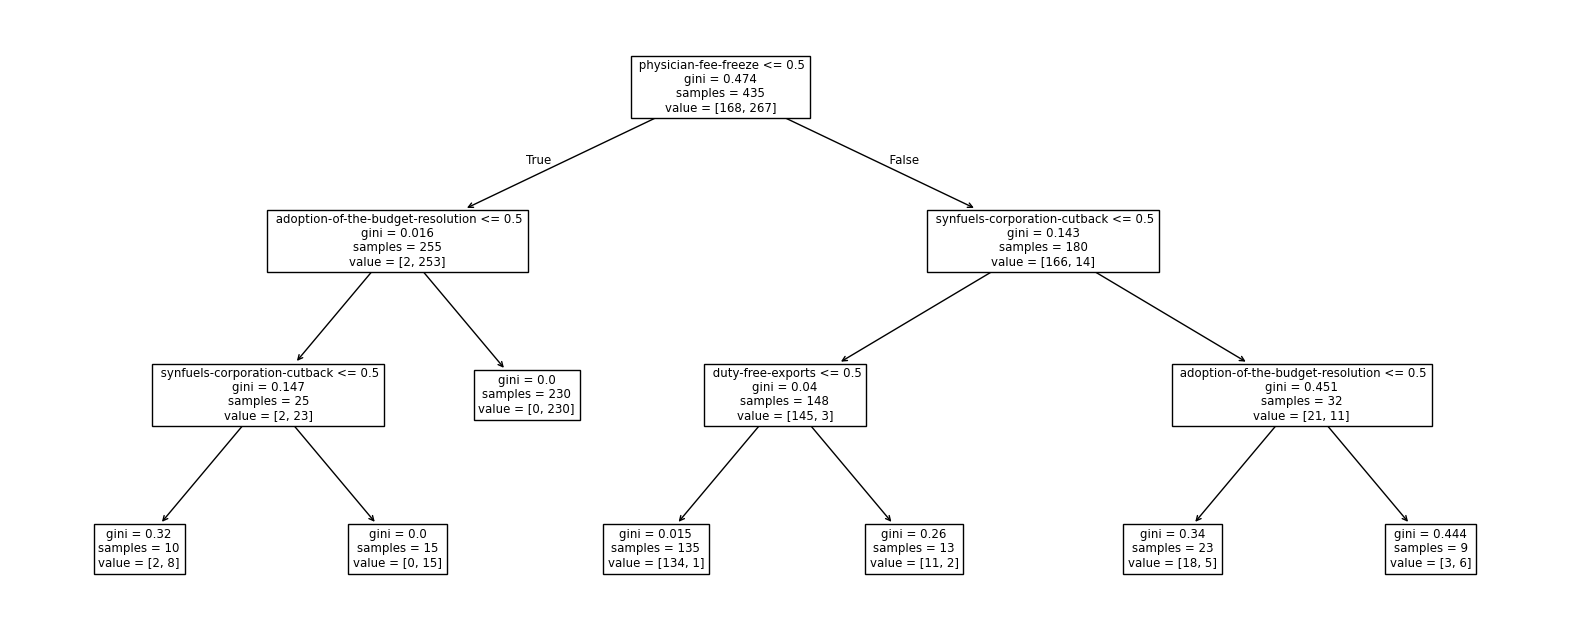

In [22]:
plt.figure(figsize=(20,8))
tree.plot_tree(model, feature_names=list(X.columns));

In [23]:
r = tree.export_text(model, feature_names=list(X.columns))
print(r)

|---  physician-fee-freeze <= 0.50
|   |---  adoption-of-the-budget-resolution <= 0.50
|   |   |---  synfuels-corporation-cutback <= 0.50
|   |   |   |--- class: 1.0
|   |   |---  synfuels-corporation-cutback >  0.50
|   |   |   |--- class: 1.0
|   |---  adoption-of-the-budget-resolution >  0.50
|   |   |--- class: 1.0
|---  physician-fee-freeze >  0.50
|   |---  synfuels-corporation-cutback <= 0.50
|   |   |---  duty-free-exports <= 0.50
|   |   |   |--- class: 0.0
|   |   |---  duty-free-exports >  0.50
|   |   |   |--- class: 0.0
|   |---  synfuels-corporation-cutback >  0.50
|   |   |---  adoption-of-the-budget-resolution <= 0.50
|   |   |   |--- class: 0.0
|   |   |---  adoption-of-the-budget-resolution >  0.50
|   |   |   |--- class: 1.0

